# Geometry of RUBRIC-DSSR class conflicts

Where RUBRIC and DSSR detect the same pair but assign different LW classes, the five other programs mostly side with RUBRIC (Fig. S3C). Agreement among programs does not show which class is right, so this notebook adds a geometric line of evidence: for every conflict, it asks whether the pair's geometry is closer to the template of RUBRIC's class or of DSSR's class.

The templates are the ones RUBRIC uses (`data/reference/basepair_idealized`, a copy of the engine's `resources/basepair-idealized`, built by `pair-finder-main-cpp/scripts/build_templates.py`). For every class and sequence, the template is the medoid of pairs from the curated reference set that the six other programs (DSSR, FR3D, RNAView, barnaba, RNApolis and BPNet) assign to that class: all six where at least five such pairs exist, otherwise five of six, four of six, or a catalog exemplar. The conflicts are the 11,602 counted in Fig. S3C.

In [1]:
import json
import sys
from pathlib import Path

import gemmi
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
SOURCE_DATA = ROOT / "figures" / "source_data"
sys.path.insert(0, str(ROOT / "scripts" / "validation"))
import consensus_shared_conflicts as conflicts
from _vendor import annotators
from figure2_comparison import Comparison

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.linewidth": 0.8, "legend.frameon": False, "axes.unicode_minus": False,
})
BLUE, ORANGE, GREY = "#4C72B0", "#DD8452", "0.75"
TIE = 0.1                 # RMSD differences within 0.1 A count as undecided
MAX_RESOLUTION = 3.0      # template pairs come from structures at this resolution or better
MIN_TEMPLATE_PAIRS = 5    # class-sequence combinations with fewer unanimous pairs get no template
SAMPLE = 300              # unanimous pairs used per class and sequence
ATOMS = {"A": ["C1'", "N9", "C8", "N7", "C5", "C6", "N6", "N1", "C2", "N3", "C4"],
         "G": ["C1'", "N9", "C8", "N7", "C5", "C6", "O6", "N1", "C2", "N2", "N3", "C4"],
         "C": ["C1'", "N1", "C2", "O2", "N3", "C4", "N4", "C5", "C6"],
         "U": ["C1'", "N1", "C2", "O2", "N3", "C4", "O4", "C5", "C6"]}


def canon(lw):
    order = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if order[lw[1]] > order[lw[2]] else lw

## Class conflicts
The same population as Fig. S3C: pairs both programs detect, with a definite DSSR class, that at least one referee program reports.

In [2]:
panels = {"fr3d": annotators.fr3d_pairs(),
          **{t: annotators.tool_pairs(t) for t in conflicts.VOTING_TOOLS}}
rows = []
for r in conflicts.class_records(conflicts.s1a_conflicts()):
    found = {t: {c for c in annotators.lookup(p[r.pdb_id], r.res1, r.res2) if not c.startswith("n")}
             for t, p in panels.items() if r.pdb_id in p}
    sides = annotators.vote_sides(r.disputed_class, r.rubric_candidates)
    if not found or sides is None:
        continue
    dssr_side, rubric_side = sides
    rows.append({"pdb": r.pdb_id, "key": tuple(sorted([(r.res1.chain, r.res1.number, r.res1.icode),
                                                      (r.res2.chain, r.res2.number, r.res2.icode)])),
                 "dssr": r.disputed_class, "rubric": [c for c in r.rubric_candidates if c not in dssr_side],
                 "votes_rubric": sum(bool(c & rubric_side) for c in found.values()),
                 "votes_dssr": sum(bool(c & dssr_side) for c in found.values())})
CONFLICTS = pd.DataFrame(rows)
print(f"{len(CONFLICTS):,} class conflicts in {CONFLICTS.pdb.nunique():,} structures")

11,507 class conflicts in 523 structures


## RUBRIC's class templates
One template per class and sequence (`<class>/<sequence>.pdb`), base atoms only; the first residue carries the first edge of the class. Symmetric classes are stored in both residue orders. `summary.json` records how each template was built (tier, number of pairs, spread).

In [3]:
comparison = Comparison(ROOT / "data")
names = comparison.residue_names
TEMPLATE_DIR = data_file("reference/basepair_idealized")


def find_residue(model, rid):
    chain = model.find_chain(rid[0])
    return next((r for r in chain or [] if r.seqid.num == rid[1] and r.seqid.icode.strip() == rid[2]), None)


def coords(res, base):
    pts = []
    for name in ATOMS[base]:
        atom = res.find_atom(name, "*")
        if atom is None:
            return None
        pts.append(atom.pos.tolist())
    return np.array(pts)


def tier_of(path):
    for line in path.read_text().splitlines():
        if line.startswith("REMARK   2 Tier"):
            return int(line.split()[3].rstrip(":"))
    return None


TEMPLATES, TIER = {}, {}
for path in sorted(TEMPLATE_DIR.glob("*/*.pdb")):
    lw, seq = path.parent.name, path.stem
    if len(seq) != 2 or not set(seq) <= set("ACGU"):
        continue
    residues = [r for ch in gemmi.read_structure(str(path))[0] for r in ch]
    if len(residues) != 2:
        continue
    xa, xb = coords(residues[0], seq[0]), coords(residues[1], seq[1])
    if xa is None or xb is None:
        continue
    TEMPLATES[(lw, seq)] = np.vstack([xa, xb])
    TIER[(lw, seq)] = tier_of(path)
print(f"{len(TEMPLATES)} templates (class and sequence, both orders for symmetric classes); by tier",
      dict(sorted(pd.Series(TIER).value_counts().items())))


178 templates (class and sequence, both orders for symmetric classes); by tier {1: 86, 2: 40, 3: 27, 4: 16, 5: 9}


## Coordinates of the conflicting pairs

In [4]:
conflict_res = {}
for pdb, group in CONFLICTS.groupby("pdb"):
    model = gemmi.read_structure(str(data_file(f"structures/{pdb}.cif")))[0]
    for r in group.itertuples():
        residues = [find_residue(model, k) for k in r.key]
        conflict_res[r.Index] = residues if None not in residues else None
print(f"coordinates for {sum(v is not None for v in conflict_res.values()):,} of {len(CONFLICTS):,} conflicts")


coordinates for 11,507 of 11,507 conflicts


## Superposition
Kabsch superposition on the base atoms of both residues.

In [5]:
def superpose(p, q):
    """Rotate/translate q onto p; return transformed q and RMSD."""
    pc, qc = p.mean(0), q.mean(0)
    u, s, vt = np.linalg.svd((q - qc).T @ (p - pc))
    d = np.sign(np.linalg.det(u @ vt))
    rot = u @ np.diag([1, 1, d]) @ vt
    moved = (q - qc) @ rot + pc
    return moved, float(np.sqrt(((moved - p) ** 2).sum(1).mean()))


## Fit of each conflict to the template of RUBRIC's class and of DSSR's class
The class labels in the conflicts are compared without orientation, as in Fig. S3C, so each class is fitted with the residues in either order and the better fit is kept.

In [6]:
def fit(lw, residues, bases):
    best = None
    for (x, bx), (y, by) in (((residues[0], bases[0]), (residues[1], bases[1])),
                              ((residues[1], bases[1]), (residues[0], bases[0]))):
        tmpl = TEMPLATES.get((canon(lw), bx + by))
        if tmpl is None:
            continue
        cx, cy = coords(x, bx), coords(y, by)
        if cx is None or cy is None:
            continue
        value = superpose(tmpl, np.vstack([cx, cy]))[1]
        best = value if best is None else min(best, value)
    return best


records = []
for r in CONFLICTS.itertuples():
    residues = conflict_res.get(r.Index)
    rec = {"pdb": r.pdb, "res1": "{}:{}{}".format(*r.key[0]), "res2": "{}:{}{}".format(*r.key[1]),
           "dssr_class": canon(r.dssr), "rubric_class": "|".join(sorted({canon(c) for c in r.rubric})),
           "votes_rubric": r.votes_rubric, "votes_dssr": r.votes_dssr}
    if residues is not None and len(r.rubric) == 1:
        bases = [names[r.pdb].get("{}|{}|{}".format(*k)) for k in r.key]
        if set(bases) <= set("ACGU"):
            rec["rmsd_dssr"], rec["rmsd_rubric"] = fit(r.dssr, residues, bases), fit(r.rubric[0], residues, bases)
    records.append(rec)
FIT = pd.DataFrame(records).dropna(subset=["rmsd_dssr", "rmsd_rubric"]).reset_index(drop=True)
FIT["difference"] = FIT.rmsd_dssr - FIT.rmsd_rubric
FIT["closer_to"] = np.select([FIT.difference > TIE, FIT.difference < -TIE], ["RUBRIC", "DSSR"], "within 0.1 A")
FIT["conflict"] = FIT.rubric_class + " (RUBRIC) vs " + FIT.dssr_class + " (DSSR)"
FIT.to_csv(SOURCE_DATA / "template_fit_class_conflicts.csv", index=False)
FIT.to_csv(data_file("validation/template_fit_class_conflicts.csv"), index=False)  # read by Fig. S3D
print(f"{len(FIT):,} of {len(CONFLICTS):,} conflicts fitted to both templates; "
      f"{(FIT.difference == 0).sum()} exact ties")

11,501 of 11,507 conflicts fitted to both templates; 0 exact ties


## Which class the geometry supports
Shares with 95% bootstrap confidence intervals (2,000 resamples of structures) and a two-sided z-test with cluster-robust variance over structures, as in Fig. S3C.

In [7]:
def summarize(df, reps=2000, seed=7):
    per = df.groupby("pdb").closer_to.agg(n="size", a=lambda s: (s == "RUBRIC").sum(),
                                          b=lambda s: (s == "DSSR").sum())
    n, a, b = (per[c].to_numpy(float) for c in ("n", "a", "b"))
    w = np.random.default_rng(seed).multinomial(len(n), np.full(len(n), 1 / len(n)), size=reps).astype(float)
    diff = (a - b).sum() / n.sum()
    u = (a - b - diff * n) / n.sum()
    p = 2 * norm.sf(abs(diff / np.sqrt(len(u) / (len(u) - 1) * (u ** 2).sum())))
    ci = lambda v: np.percentile(100 * (w @ v) / (w @ n), [2.5, 97.5]).round(1)
    return {"pairs": int(n.sum()), "structures": len(n),
            "closer to RUBRIC (%)": round(100 * a.sum() / n.sum(), 1), "95% CI RUBRIC": ci(a),
            "closer to DSSR (%)": round(100 * b.sum() / n.sum(), 1), "95% CI DSSR": ci(b),
            "within 0.1 A (%)": round(100 * (n - a - b).sum() / n.sum(), 1),
            "p (cluster-robust)": "< 0.0001" if p < 1e-4 else f"{p:.2g}"}


LARGEST = FIT.conflict.value_counts().index[0]
SUMMARY = pd.DataFrame({"all conflicts": summarize(FIT),
                        f"excluding {LARGEST}": summarize(FIT[FIT.conflict != LARGEST])}).T
print("median RMSD to the template of RUBRIC's class:", FIT.rmsd_rubric.median().round(2), "A")
print("median RMSD to the template of DSSR's class:   ", FIT.rmsd_dssr.median().round(2), "A")
SUMMARY

median RMSD to the template of RUBRIC's class: 0.61 A
median RMSD to the template of DSSR's class:    1.61 A


,pairs,structures,closer to RUBRIC (%),95% CI RUBRIC,closer to DSSR (%),95% CI DSSR,within 0.1 A (%),p (cluster-robust)
all conflicts,11501,523,81.3,"[80.5, 82.1]",15.0,"[14.4, 15.8]",3.7,< 0.0001
excluding tSS (RUBRIC) vs tWS (DSSR),6695,499,67.8,"[66.7, 69.0]",25.8,"[24.8, 26.9]",6.3,< 0.0001


## By conflict type
Conflict types with at least 100 pairs.

In [8]:
BY_TYPE = (FIT.groupby("conflict").closer_to.value_counts(normalize=True).unstack(fill_value=0)
           .mul(100).round(1).join(FIT.conflict.value_counts().rename("pairs")))
BY_TYPE[BY_TYPE.pairs >= 100].sort_values("pairs", ascending=False)[["pairs", "RUBRIC", "DSSR", "within 0.1 A"]]

,pairs,RUBRIC,DSSR,within 0.1 A
conflict,,,,
tSS (RUBRIC) vs tWS (DSSR),4806,100.0,0.0,0.0
cWS (RUBRIC) vs cWW (DSSR),1321,91.8,4.2,3.9
tHS (RUBRIC) vs tWH (DSSR),1274,85.1,0.9,14.1
cSS (RUBRIC) vs cWS (DSSR),732,96.9,0.8,2.3
tWS (RUBRIC) vs tWW (DSSR),496,88.1,8.3,3.6
tHS (RUBRIC) vs tWS (DSSR),421,64.8,34.9,0.2
cHS (RUBRIC) vs cWH (DSSR),333,63.7,24.0,12.3
tWW (RUBRIC) vs tWH (DSSR),285,5.3,93.7,1.1
tWS (RUBRIC) vs tHS (DSSR),222,56.3,41.4,2.3


## Agreement with the referee programs
The referee verdict is the class supported by more of the five other programs. Rows are referee verdicts, columns the geometric verdict.

In [9]:
FIT["referees"] = np.select([FIT.votes_rubric > FIT.votes_dssr, FIT.votes_rubric < FIT.votes_dssr],
                            ["RUBRIC", "DSSR"], "tie")
pd.crosstab(FIT.referees, FIT.closer_to, margins=True)

closer_to,DSSR,RUBRIC,within 0.1 A,All
referees,,,,
DSSR,778,1293,99,2170
RUBRIC,542,6455,165,7162
tie,410,1600,159,2169
All,1730,9348,423,11501


## Figure
(A) RMSD of each conflict to the template of RUBRIC's class against that of DSSR's class; pairs above the diagonal are closer to RUBRIC's class. (B) The same comparison as one number per pair: the difference between the two RMSDs, positive when the pair is closer to RUBRIC's class. Grey bars are within 0.1 Å.

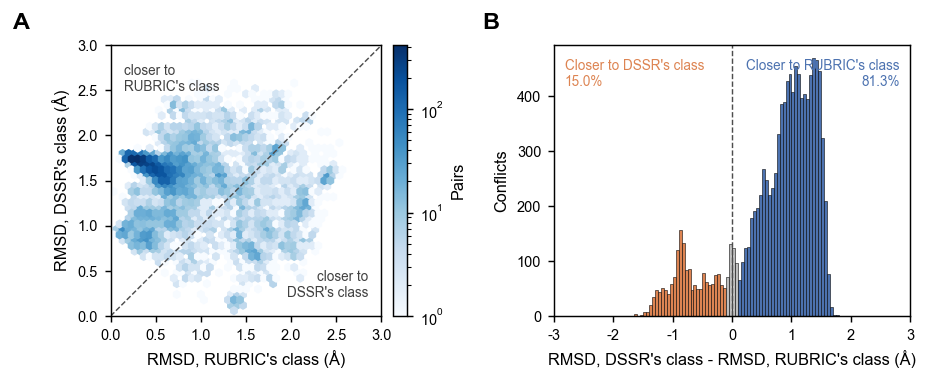

In [10]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw={"width_ratios": [1, 1.2]})
hi = float(np.ceil(np.nanpercentile(FIT[["rmsd_rubric", "rmsd_dssr"]].to_numpy(), 99.5)))
hb = ax_a.hexbin(FIT.rmsd_rubric, FIT.rmsd_dssr, gridsize=45, extent=(0, hi, 0, hi), mincnt=1,
                 bins="log", cmap="Blues")
ax_a.plot([0, hi], [0, hi], color="0.3", lw=0.8, ls="--")
ax_a.set(xlim=(0, hi), ylim=(0, hi), aspect="equal",
         xlabel="RMSD, RUBRIC's class (Å)", ylabel="RMSD, DSSR's class (Å)")
fig.colorbar(hb, ax=ax_a, fraction=0.046, pad=0.04).set_label("Pairs")
ax_a.text(0.05 * hi, 0.93 * hi, "closer to\nRUBRIC's class", va="top", fontsize=7.5, color="0.25")
ax_a.text(0.95 * hi, 0.07 * hi, "closer to\nDSSR's class", ha="right", fontsize=7.5, color="0.25")

edges = np.arange(-3.0, 3.0001, 0.05)
counts, _ = np.histogram(FIT.difference.clip(-2.999, 2.999), bins=edges)
centres = (edges[:-1] + edges[1:]) / 2
colors = np.where(centres > TIE, BLUE, np.where(centres < -TIE, ORANGE, GREY))
ax_b.bar(centres, counts, width=0.05, color=colors, edgecolor="black", linewidth=0.3)
ax_b.axvline(0, color="0.3", lw=0.8, ls="--")
share = FIT.closer_to.value_counts(normalize=True) * 100
ax_b.text(0.97, 0.95, f"Closer to RUBRIC's class\n{share.get('RUBRIC', 0):.1f}%", transform=ax_b.transAxes,
          ha="right", va="top", fontsize=7.5, color=BLUE)
ax_b.text(0.03, 0.95, f"Closer to DSSR's class\n{share.get('DSSR', 0):.1f}%", transform=ax_b.transAxes,
          ha="left", va="top", fontsize=7.5, color=ORANGE)
ax_b.set(xlim=(-3, 3), xlabel="RMSD, DSSR's class - RMSD, RUBRIC's class (Å)", ylabel="Conflicts")
for ax, s in ((ax_a, "A"), (ax_b, "B")):
    ax.text(-0.36 if s == "A" else -0.2, 1.06, s, transform=ax.transAxes, fontsize=13, fontweight="bold")
fig.tight_layout()
out = ROOT / "figures" / "analysis" / "template_fit_class_conflicts.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out)
plt.show()

## Caveats
- The templates are built from pairs that the six other programs agree on, so RUBRIC's own class assignments play no part in them. DSSR is one of the six, so where a conflict pair resembles pairs that DSSR and the others agree on, the test favours DSSR, as it should.
- RUBRIC uses the same templates when it classifies (for example, to resolve some sugar-edge ambiguities), so for those conflicts the comparison is not independent of how RUBRIC chose the class.
- Classes are compared without orientation, as in Fig. S3C.
- Conflicts without a template for both classes are left out; the count is printed above.
- The largest conflict type (tSS in RUBRIC, tWS in DSSR) dominates the overall share, so the result is also given without it.